
# DATA 266 — Homework 12
## Part 1: LLM Optimization with GPTQ — Speed and Accuracy Comparison (5 Points)



In this experiment, we will apply GPTQ post-training quantization to an instructor-approved large language model (LLM) and compare its performance before and after quantization.

The goal is to understand how reducing the model's weight precision affects language-model quality, inference latency, GPU memory consumption, and storage size.



## Step 0 — Environment Setup and Verification




In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import torch
import sys
import importlib.metadata as md

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

GPTQ_DIR = ROOT / "outputs/part1_gptq"
GPTQ_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("DATA 266 HW12 — GPTQ ENVIRONMENT CHECK")
print("=" * 60)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    free, total = torch.cuda.mem_get_info()

    print(f"Free GPU memory: {free / 1024**3:.2f} GiB")
    print(f"Total GPU memory: {total / 1024**3:.2f} GiB")

for package in [
    "transformers",
    "datasets",
    "accelerate",
    "gptqmodel",
    "optimum"
]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: Not installed")

print("\nGPTQ output directory:", GPTQ_DIR)
print("Directory exists:", GPTQ_DIR.exists())

print("=" * 60)

Mounted at /content/drive
DATA 266 HW12 — GPTQ ENVIRONMENT CHECK
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA L4
Free GPU memory: 21.84 GiB
Total GPU memory: 22.03 GiB
transformers: 5.22.1
datasets: 4.8.5
accelerate: 1.15.0
gptqmodel: Not installed
optimum: Not installed

GPTQ output directory: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq
Directory exists: True



## Part 1, Question 1 — Base LLM Selection and Verification

### Objective

The first task is to identify and verify the instructor-approved base language model for GPTQ quantization.

We must use exactly the same original model for both the unquantized and GPTQ-quantized experiments so that differences in accuracy, latency, memory, and disk size can be attributed to quantization rather than changes in model architecture.

### Procedure

1. Identify the instructor-provided or instructor-approved Hugging Face model.
2. Record its exact repository ID and revision.
3. Inspect its architecture, parameter count, and model configuration.
4. Confirm that the model can fit within the available NVIDIA L4 GPU resources.
5. Use WikiText-2 for calibration and evaluation, keeping the calibration and evaluation samples separate.

### Model Details

- Base model ID: To be verified
- Model revision: To be verified
- Architecture: To be verified
- Original precision: To be verified
- Quantization method: GPTQ
- Target weight precision: 4-bit
- Hardware: NVIDIA L4 GPU

### Expected Result

A verified base LLM configuration that can be used consistently throughout the GPTQ experiment.

No quantization or model-quality results will be reported until the approved model is loaded and tested.


In [ ]:
# ============================================================
# DATA 266 — HOMEWORK 12
# STEP 0: PERSONAL PARAMETERS AND REPRODUCIBILITY
# ============================================================

import random
import numpy as np
import torch

# Replace None with the last four digits of your SJSU ID.
# Keep this value consistent across all HW12 notebooks.
SID4 = 1598

if SID4 is None:
    raise ValueError("Set SID4 before running this notebook.")

SID4 = int(SID4)

assert 0 <= SID4 <= 9999

SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6

CLS_A = SID4 % 10
CLS_B = (
    CLS_A + 1 + ((SID4 // 10) % 9)
) % 10

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 55)
print("DATA 266 — HW12 PERSONAL PARAMETERS")
print("=" * 55)

print("SID4  =", f"{SID4:04d}")
print("SEED  =", SEED)
print("SLICE =", SLICE)
print("HP_ID =", HP_ID)
print("CLS_A =", CLS_A)
print("CLS_B =", CLS_B)

print("\nRandom seeds configured successfully.")
print("=" * 55)

DATA 266 — HW12 PERSONAL PARAMETERS
SID4  = 1598
SEED  = 1598
SLICE = 598
HP_ID = 2
CLS_A = 8
CLS_B = 5

Random seeds configured successfully.


In [ ]:
from huggingface_hub import HfApi
import json
from pathlib import Path

assert "SID4" in globals() and isinstance(SID4, int), (
    "Run the personal-parameters cell first."
)
assert SEED == SID4, "SEED must equal SID4."

MODEL_ID = "facebook/opt-125m"

api = HfApi()
info = api.model_info(MODEL_ID)

MODEL_REVISION = info.sha

metadata = {
    "model_id": MODEL_ID,
    "revision": MODEL_REVISION,
    "model_family": "OPT",
    "quantization_method": "GPTQ",
    "target_bits": 4,
    "instructor_approval": "Not yet confirmed",
    "seed": SEED,
    "hardware": "NVIDIA L4"
}

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("=" * 60)
print("GPTQ — BASE MODEL VERIFICATION")
print("=" * 60)

print("Model ID:", MODEL_ID)
print("Exact revision:", MODEL_REVISION)
print("Model private:", info.private)
print("Quantization target: 4-bit GPTQ")
print("GPU: NVIDIA L4")
print("Metadata saved:", OUTPUT_DIR / "model_metadata.json")

print("=" * 60)

GPTQ — BASE MODEL VERIFICATION
Model ID: facebook/opt-125m
Exact revision: 27dcfa74d334bc871f3234de431e71c6eeba5dd6
Model private: False
Quantization target: 4-bit GPTQ
GPU: NVIDIA L4
Metadata saved: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/model_metadata.json



## Part 1 — Question 1: Load the Original Language Model


Load the original, unquantized causal language model and verify its architecture, parameter count, precision, and memory requirements.



- Model ID: `facebook/opt-125m`
- Revision: `27dcfa74d334bc871f3234de431e71c6eeba5dd6`
- Architecture: OPT causal language model
- Precision: FP16
- Device: NVIDIA L4 GPU
- Random seed: 1598

We load the model using Hugging Face Transformers with the exact recorded revision.

The original FP16 model will serve as the reference for evaluating the effect of GPTQ 4-bit weight quantization.

We will use identical evaluation data and comparable benchmarking settings for the original and quantized models.



In [ ]:
import gc
import json
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

# =====================================================
# 1. CONFIGURATION
# =====================================================

MODEL_ID = "facebook/opt-125m"

MODEL_REVISION = (
    "27dcfa74d334bc871f3234de431e71c6eeba5dd6"
)

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")

OUTPUT_DIR = ROOT / "outputs/part1_gptq"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert SEED == SID4, "Personal seed is not configured."
assert torch.cuda.is_available(), "GPU runtime required."

device = torch.device("cuda")

gc.collect()
torch.cuda.empty_cache()

# =====================================================
# 2. LOAD TOKENIZER
# =====================================================

print("Loading original OPT tokenizer...")

opt_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION
)

# =====================================================
# 3. LOAD ORIGINAL FP16 MODEL
# =====================================================

print("Loading original FP16 model...")

original_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=torch.float16
)

original_model = original_model.to(device)
original_model.eval()

# =====================================================
# 4. VERIFY MODEL
# =====================================================

total_parameters = sum(
    p.numel() for p in original_model.parameters()
)

parameter_dtype = next(
    original_model.parameters()
).dtype

allocated_gib = (
    torch.cuda.memory_allocated() / 1024**3
)

print("\n" + "=" * 65)
print("ORIGINAL LLM — MODEL VERIFICATION")
print("=" * 65)

print("Model ID:", MODEL_ID)
print("Revision:", MODEL_REVISION)
print("Architecture:", original_model.config.architectures)
print("Model type:", original_model.config.model_type)

print(f"Parameters: {total_parameters:,}")
print("Precision:", parameter_dtype)
print("GPU:", torch.cuda.get_device_name(0))

print(
    f"Current allocated GPU memory: "
    f"{allocated_gib:.3f} GiB"
)

print(
    "Vocabulary size:",
    original_model.config.vocab_size
)

print(
    "Hidden layers:",
    original_model.config.num_hidden_layers
)

print("=" * 65)

# =====================================================
# 5. SAVE MODEL METADATA
# =====================================================

metadata_path = OUTPUT_DIR / "original_model_info.json"

metadata = {
    "model_id": MODEL_ID,
    "revision": MODEL_REVISION,
    "precision": str(parameter_dtype),
    "parameters": total_parameters,
    "architecture": original_model.config.architectures,
    "model_type": original_model.config.model_type,
    "vocab_size": original_model.config.vocab_size,
    "num_hidden_layers": original_model.config.num_hidden_layers,
    "gpu": torch.cuda.get_device_name(0),
    "seed": SEED
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("\n✅ Original model loaded successfully!")
print("✅ Model metadata saved:", metadata_path)

Loading original OPT tokenizer...


config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

... (2 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]


ORIGINAL LLM — MODEL VERIFICATION
Model ID: facebook/opt-125m
Revision: 27dcfa74d334bc871f3234de431e71c6eeba5dd6
Architecture: ['OPTForCausalLM']
Model type: opt
Parameters: 125,239,296
Precision: torch.float16
GPU: NVIDIA L4
Current allocated GPU memory: 0.240 GiB
Vocabulary size: 50272
Hidden layers: 12

✅ Original model loaded successfully!
✅ Model metadata saved: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/original_model_info.json



## Part 1 — Question 2: WikiText-2 Dataset Preparation


Prepare the WikiText-2 dataset for GPTQ calibration and language-model evaluation.

### Dataset

- Dataset repository: `Salesforce/wikitext`
- Configuration: `wikitext-2-raw-v1`
- Calibration source: Training split
- Perplexity evaluation: Test split
- Random seed: 1598
- Model tokenizer: `facebook/opt-125m`


We use the WikiText-2 training split to select calibration text for GPTQ quantization. The test split is kept separate to measure the original and quantized model's language-modeling performance.

Empty text records are excluded from calibration. Calibration samples are selected reproducibly using the student-specific seed.

The same held-out test text and tokenization procedure will be used for both FP16 and GPTQ models.




In [ ]:
import json
import random
from pathlib import Path

import numpy as np
from datasets import load_dataset

# =====================================================
# 1. CONFIGURATION
# =====================================================

DATASET_ID = "Salesforce/wikitext"
DATASET_CONFIG = "wikitext-2-raw-v1"

CALIBRATION_SAMPLES = 128
CALIBRATION_MAX_TOKENS = 256

assert SEED == SID4 == 1598
assert opt_tokenizer is not None

random.seed(SEED)
np.random.seed(SEED)

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
DATA_DIR = ROOT / "outputs/part1_gptq/dataset"

DATA_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# 2. LOAD WIKITEXT-2
# =====================================================

print("Loading WikiText-2 dataset...")

wikitext = load_dataset(
    DATASET_ID,
    DATASET_CONFIG
)

print("\n" + "=" * 60)
print("WIKITEXT-2 DATASET INFORMATION")
print("=" * 60)

for split_name in ["train", "validation", "test"]:
    print(
        f"{split_name:<12}: "
        f"{len(wikitext[split_name]):,} records"
    )

# =====================================================
# 3. PREPARE CALIBRATION TEXT
# =====================================================

# Keep substantive text records from training only.
train_texts = [
    text.strip()
    for text in wikitext["train"]["text"]
    if text and text.strip()
]

# Require at least 32 tokens to avoid tiny calibration samples.
eligible_texts = []

for text in train_texts:
    ids = opt_tokenizer(
        text,
        add_special_tokens=False
    )["input_ids"]

    if len(ids) >= 32:
        eligible_texts.append(text)

assert len(eligible_texts) >= CALIBRATION_SAMPLES

# Reproducible selection using the student's seed.
rng = random.Random(SEED)

selected_indices = rng.sample(
    range(len(eligible_texts)),
    CALIBRATION_SAMPLES
)

calibration_texts = [
    eligible_texts[i]
    for i in selected_indices
]

# Truncate calibration text to a common token budget.
calibration_ids = opt_tokenizer(
    calibration_texts,
    truncation=True,
    max_length=CALIBRATION_MAX_TOKENS,
    add_special_tokens=False
)["input_ids"]

calibration_texts = [
    opt_tokenizer.decode(
        ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )
    for ids in calibration_ids
]

# =====================================================
# 4. VERIFY HELD-OUT TEST DATA
# =====================================================

test_texts = [
    text
    for text in wikitext["test"]["text"]
    if text and text.strip()
]

assert len(test_texts) > 0

print("\nCalibration samples:", len(calibration_texts))
print("Nonempty test records:", len(test_texts))

print("\nFirst calibration sample:")
print(calibration_texts[0][:350])

# =====================================================
# 5. SAVE CALIBRATION DATA
# =====================================================

calibration_path = DATA_DIR / "gptq_calibration_texts.json"

with open(calibration_path, "w", encoding="utf-8") as f:
    json.dump(
        calibration_texts,
        f,
        indent=2,
        ensure_ascii=False
    )

metadata = {
    "dataset": DATASET_ID,
    "configuration": DATASET_CONFIG,
    "calibration_split": "train",
    "evaluation_split": "test",
    "seed": SEED,
    "calibration_samples": CALIBRATION_SAMPLES,
    "calibration_max_tokens": CALIBRATION_MAX_TOKENS,
    "selected_eligible_indices": selected_indices,
    "base_model": MODEL_ID,
    "base_model_revision": MODEL_REVISION
}

metadata_path = DATA_DIR / "dataset_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

# =====================================================
# 6. FINAL VERIFICATION
# =====================================================

assert len(calibration_texts) == 128
assert all(text.strip() for text in calibration_texts)

print("\n" + "=" * 60)
print("WIKITEXT-2 PREPARATION — COMPLETE")
print("=" * 60)

print("Calibration samples:", len(calibration_texts))
print("Evaluation split: test")
print("Random seed:", SEED)
print("Calibration and test splits: SEPARATE")

print("\nSaved calibration data:", calibration_path)
print("Saved metadata:", metadata_path)

print("=" * 60)

Loading WikiText-2 dataset...


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]


WIKITEXT-2 DATASET INFORMATION
train       : 36,718 records
validation  : 3,760 records
test        : 4,358 records

Calibration samples: 128
Nonempty test records: 2891

First calibration sample:
Gamma emission from the radioisotope 133Xe of xenon can be used to image the heart , lungs , and brain , for example , by means of single photon emission computed tomography . 133Xe has also been used to measure blood flow .

WIKITEXT-2 PREPARATION — COMPLETE
Calibration samples: 128
Evaluation split: test
Random seed: 1598
Calibration and test splits: SEPARATE

Saved calibration data: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/dataset/gptq_calibration_texts.json
Saved metadata: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/dataset/dataset_metadata.json



## Part 1 — Question 3: Original Model Quality — WikiText-2 Loss and Perplexity



Evaluate the original FP16 OPT-125M language model on the held-out WikiText-2 test split.

The goal is to establish a reproducible model-quality baseline before applying GPTQ 4-bit quantization.



1. Load the WikiText-2 test split.
2. Tokenize the test text using the original model's tokenizer.
3. Evaluate the model using overlapping context windows.
4. Calculate the average next-token negative log-likelihood (NLL).
5. Calculate perplexity from the average NLL.
6. Save the measured results and evaluation configuration.



**Cross-entropy / negative log-likelihood:** Measures how well the model predicts the next token. Lower loss indicates better predictions.

**Perplexity (PPL):**

PPL = exp(average next-token NLL)

Lower perplexity indicates better language-modeling performance.



In [ ]:
import json
import math
import torch

from pathlib import Path
from tqdm.auto import tqdm

# =====================================================
# 1. VERIFY MODEL AND DATA
# =====================================================

assert original_model is not None
assert opt_tokenizer is not None
assert "wikitext" in globals()
assert SEED == SID4 == 1598

original_model.eval()

EVAL_WINDOW = 1024
EVAL_STRIDE = 512

assert EVAL_WINDOW <= original_model.config.max_position_embeddings
assert 0 < EVAL_STRIDE <= EVAL_WINDOW

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# 2. TOKENIZE COMPLETE TEST SPLIT
# =====================================================

print("Preparing full WikiText-2 test text...")

test_text = "\n\n".join(wikitext["test"]["text"])

# Keep this same token sequence for both models.
eval_input_ids = opt_tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False,
    truncation=False
)["input_ids"]

print("Total evaluation tokens:", eval_input_ids.size(1))

# =====================================================
# 3. REUSABLE PERPLEXITY FUNCTION
# =====================================================

def evaluate_wikitext_perplexity(
    model,
    input_ids,
    window_length=1024,
    stride=512
):
    model.eval()
    model_device = next(model.parameters()).device

    sequence_length = input_ids.size(1)

    total_nll = 0.0
    total_scored_tokens = 0
    total_windows = 0

    previous_end = 0

    for end in tqdm(
        range(stride, sequence_length + stride, stride),
        desc="Evaluating WikiText-2"
    ):
        begin = max(end - window_length, 0)
        end = min(end, sequence_length)

        target_length = end - previous_end

        if target_length <= 0:
            break

        batch = input_ids[:, begin:end].to(model_device)

        labels = batch.clone()

        # Score only newly encountered tokens.
        # Earlier tokens provide context.
        labels[:, :-target_length] = -100

        # Causal LM loss shifts labels by one token.
        scored_tokens = int(
            (labels[:, 1:] != -100).sum().item()
        )

        with torch.inference_mode():
            outputs = model(
                input_ids=batch,
                labels=labels,
                use_cache=False
            )

        if scored_tokens > 0:
            total_nll += (
                float(outputs.loss.item()) * scored_tokens
            )
            total_scored_tokens += scored_tokens

        total_windows += 1
        previous_end = end

        if end == sequence_length:
            break

    assert total_scored_tokens > 0

    average_nll = total_nll / total_scored_tokens

    return {
        "average_nll": average_nll,
        "perplexity": math.exp(average_nll),
        "total_evaluation_tokens": sequence_length,
        "scored_tokens": total_scored_tokens,
        "evaluation_windows": total_windows,
        "window_length": window_length,
        "stride": stride
    }


# =====================================================
# 4. RUN ORIGINAL FP16 EVALUATION
# =====================================================

print("\nEvaluating original FP16 OPT model...")

fp16_results = evaluate_wikitext_perplexity(
    original_model,
    eval_input_ids,
    window_length=EVAL_WINDOW,
    stride=EVAL_STRIDE
)

# =====================================================
# 5. DISPLAY RESULTS
# =====================================================

print("\n" + "=" * 65)
print("ORIGINAL FP16 — WIKITEXT-2 QUALITY RESULTS")
print("=" * 65)

print("Model:", MODEL_ID)
print("Precision: FP16")
print("Dataset: WikiText-2 test")

print(
    "Total tokens:",
    fp16_results["total_evaluation_tokens"]
)

print(
    "Scored tokens:",
    fp16_results["scored_tokens"]
)

print(
    "Evaluation windows:",
    fp16_results["evaluation_windows"]
)

print(
    f"Average NLL: {fp16_results['average_nll']:.6f}"
)

print(
    f"Perplexity: {fp16_results['perplexity']:.4f}"
)

print("=" * 65)

# =====================================================
# 6. SAVE RESULTS
# =====================================================

fp16_results.update({
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "precision": "FP16",
    "dataset": "Salesforce/wikitext",
    "dataset_config": "wikitext-2-raw-v1",
    "dataset_split": "test",
    "seed": SEED
})

results_path = OUTPUT_DIR / "fp16_wikitext_metrics.json"

with open(results_path, "w") as f:
    json.dump(fp16_results, f, indent=2)

print("\n✅ Original FP16 evaluation complete!")
print("✅ Results saved:", results_path)

Preparing full WikiText-2 test text...
Total evaluation tokens: 287644

Evaluating original FP16 OPT model...


Evaluating WikiText-2:   0%|          | 0/562 [00:00<?, ?it/s]


ORIGINAL FP16 — WIKITEXT-2 QUALITY RESULTS
Model: facebook/opt-125m
Precision: FP16
Dataset: WikiText-2 test
Total tokens: 287644
Scored tokens: 287643
Evaluation windows: 562
Average NLL: 3.262074
Perplexity: 26.1036

✅ Original FP16 evaluation complete!
✅ Results saved: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/fp16_wikitext_metrics.json



## Part 1 — Question 4: GPTQ Quantization — Environment and Dependency Verification



Prepare a compatible software environment for GPTQ 4-bit post-training quantization of the original OPT-125M language model.


### Procedure

1. Inspect the installed library versions.
2. Verify the GPTQModel dependency requirements.
3. Install compatible packages without unintentionally breaking the GPU runtime.
4. Verify successful imports and CUDA support.
5. Apply 4-bit GPTQ quantization using the previously saved calibration samples.
6. Save and reload the quantized model.


In [ ]:
import sys
import subprocess
import importlib.metadata as md
from pathlib import Path
from datetime import datetime, timezone

print("=" * 65)
print("GPTQ PACKAGE COMPATIBILITY CHECK")
print("=" * 65)

for package in [
    "torch",
    "transformers",
    "accelerate",
    "datasets",
    "gptqmodel",
    "optimum"
]:
    try:
        print(f"{package:<15}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package:<15}: Not installed")

print("\nChecking proposed GPTQModel installation...")
print("This is a dry run; no packages will be installed.")

command = [
    sys.executable,
    "-m",
    "pip",
    "install",
    "--dry-run",
    "--no-build-isolation",
    "gptqmodel",
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=180
)

print("\n" + "=" * 65)
print("INSTALLATION DRY-RUN RESULTS")
print("=" * 65)

print("Return code:", result.returncode)

combined_output = result.stdout + "\n" + result.stderr
print(combined_output[-12000:])

log_dir = Path(
    "/content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/logs"
)
log_dir.mkdir(parents=True, exist_ok=True)

log_path = log_dir / "gptq_dependency_dry_run.txt"

with open(log_path, "w", encoding="utf-8") as f:
    f.write(
        "Timestamp UTC: "
        + datetime.now(timezone.utc).isoformat()
        + "\n"
    )
    f.write("Command: " + " ".join(command) + "\n")
    f.write("Return code: " + str(result.returncode) + "\n")
    f.write(combined_output)

print("\nDependency check saved:", log_path)
print("=" * 65)

GPTQ PACKAGE COMPATIBILITY CHECK
torch          : 2.14.1+cu130
transformers   : 5.22.1
accelerate     : 1.15.0
datasets       : 4.8.5
gptqmodel      : Not installed
optimum        : Not installed

Checking proposed GPTQModel installation...
This is a dry run; no packages will be installed.

INSTALLATION DRY-RUN RESULTS
Return code: 0
tatus 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Would install Defuser-0.0.32 Device-SMI-0.5.7 GPTQModel-7.12.0 LogBar-0.4.16 PyPcre-0.6.6 TokeNicer-0.0.21 cuda-toolkit-13.2.2 datasets-5.2.0 ninja-1.13.2 nvidia-cublas-13.4.1.3 nvidia-cuda-cupti-13.2.86 nvidia-cuda-nvrtc-13.2.86 nvidia-cuda-runtime-13.2.86 nvidia-cudnn-cu13-9.26.0.51 nvidia-cufft-12.2.0.57 nvidia-cufile-1.17.1.22 nvidia-cusolver-12.2.0.11 nvidia-cusparse-12.7.10.12 nvidia-nvshmem-cu13-3.7.2 nvidia-nvtx


## Part 1 — Question 4: GPTQ Dependency Installation



Install a compatible GPTQModel environment for 4-bit post-training quantization of the original OPT-125M model.



The initial Google Colab runtime contained PyTorch 2.14.1, Transformers 5.22.1, and no GPTQModel installation.

A dependency dry run completed successfully and identified GPTQModel 7.12.0, PyTorch 2.15.0, Transformers 5.23.0, and supporting CUDA packages as a compatible candidate installation set.

### Procedure

1. Save the original FP16 baseline measurements before making environment changes.
2. Install GPTQModel with its required dependencies.
3. Restart the Colab runtime to activate the installed versions.
4. Verify package imports, GPU availability, and version compatibility.
5. Record any installation failures and corrections.



In [ ]:
import subprocess
import sys
from pathlib import Path
from datetime import datetime, timezone

log_dir = Path(
    "/content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/logs"
)
log_dir.mkdir(parents=True, exist_ok=True)

command = [
    sys.executable,
    "-m", "pip", "install",
    "gptqmodel==7.12.0",
    "--no-build-isolation"
]

print("Installing GPTQModel and compatible dependencies...")
print("Command:", " ".join(command))

result = subprocess.run(
    command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

log_path = log_dir / "gptq_installation_log.txt"

with open(log_path, "w", encoding="utf-8") as f:
    f.write("Timestamp UTC: " + datetime.now(timezone.utc).isoformat() + "\n")
    f.write("Command: " + " ".join(command) + "\n\n")
    f.write(result.stdout)
    f.write("\nReturn code: " + str(result.returncode) + "\n")

print(result.stdout[-10000:])
print("\nReturn code:", result.returncode)
print("Log saved:", log_path)

if result.returncode != 0:
    print("Installation failed. Do not proceed to quantization.")
else:
    print("Installation completed. Runtime restart required.")

Installing GPTQModel and compatible dependencies...
Command: /usr/bin/python3 -m pip install gptqmodel==7.12.0 --no-build-isolation
g nvidia_cublas-13.4.1.3-py3-none-manylinux_2_27_x86_64.whl (404.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 54.0 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 109.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 MB 116.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 99.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 MB 65.7 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 227.9/227.9 MB 67.4 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.0/151.0 MB 108.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.7/285.7 MB 58.9 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 130.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━


## Part 1 — Question 4: Post-Installation GPTQ Verification



Verify that GPTQModel and its dependencies work correctly after installation and runtime restart.

### Installation Results

GPTQModel 7.12.0 installed successfully. The installation updated PyTorch, Transformers, Datasets, CUDA libraries, and related dependencies.

Pip reported compatibility conflicts involving some preinstalled Colab packages. These warnings are documented and will be checked rather than ignored.

### Verification Procedure

1. Restart the Colab runtime.
2. Verify the NVIDIA L4 GPU and CUDA availability.
3. Confirm installed package versions.
4. Import GPTQModel and GPTQConfig.
5. Reconnect Google Drive and locate the saved model metadata, calibration data, and FP16 baseline.
6. Record verification results and any errors.




In [ ]:
import sys
import json
import traceback
import importlib.metadata as md
from pathlib import Path

print("=" * 65)
print("DATA266 HW12 — POST-INSTALLATION GPTQ VERIFICATION")
print("=" * 65)

packages = [
    "torch",
    "transformers",
    "datasets",
    "accelerate",
    "gptqmodel",
    "triton"
]

for package in packages:
    try:
        print(f"{package:<15}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package:<15}: NOT INSTALLED")

print("\nPython:", sys.version.split()[0])

try:
    import torch

    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "Free GPU memory:",
            round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
            "GiB"
        )

    from gptqmodel import GPTQModel, QuantizeConfig
    print("GPTQModel import: PASS")
    print("QuantizeConfig import: PASS")

except Exception as e:
    print("GPTQ import/runtime: FAILED")
    print("Error:", repr(e))
    traceback.print_exc()

# Reconnect Google Drive only after checking GPTQ imports.
try:
    from google.colab import drive

    drive.mount("/content/drive")

    ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
    OUTPUT_DIR = ROOT / "outputs/part1_gptq"

    expected = {
        "Model metadata": OUTPUT_DIR / "model_metadata.json",
        "FP16 baseline": OUTPUT_DIR / "fp16_wikitext_metrics.json",
        "Calibration samples": (
            OUTPUT_DIR / "dataset/gptq_calibration_texts.json"
        ),
        "Dataset metadata": (
            OUTPUT_DIR / "dataset/dataset_metadata.json"
        )
    }

    print("\nSaved experiment artifacts:")

    for name, path in expected.items():
        print(
            f"{name}:",
            "FOUND" if path.is_file() else "MISSING"
        )

    if expected["FP16 baseline"].is_file():
        with open(expected["FP16 baseline"]) as f:
            baseline = json.load(f)

        print(
            "\nSaved FP16 perplexity:",
            baseline["perplexity"]
        )

except Exception as e:
    print("\nGoogle Drive verification: FAILED")
    print("Error:", repr(e))
    traceback.print_exc()

print("=" * 65)

DATA266 HW12 — POST-INSTALLATION GPTQ VERIFICATION
torch          : 2.15.0
transformers   : 5.23.0
datasets       : 5.2.0
accelerate     : 1.15.0
gptqmodel      : 7.12.0
triton         : 3.9.0

Python: 3.13.16
CUDA available: True
GPU: NVIDIA L4
Free GPU memory: 21.84 GiB

INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.


W1119 20:47:06.724000 18200 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1119 20:47:06.764000 18200 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
GPTQ import/runtime: FAILED
Error: ModuleNotFoundError("Could not import module 'AutoProcessor'. Are this object's requirements defined correctly? Set the logging verbosity to DEBUG for the original import error.")


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/transformers/utils/import_utils.py", line 2704, in __getattr__
    module = self._get_module(self._class_to_module[name])
  File "/usr/local/lib/python3.13/dist-packages/transformers/utils/import_utils.py", line 2935, in _get_module
    raise e
  File "/usr/local/lib/python3.13/dist-packages/transformers/utils/import_utils.py", line 2933, in _get_module
    return importlib.import_module("." + module_name, self.__name__)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/importlib/__init__.py", line 88, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1404, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1369, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1340, in _find_and_load_unlocked
  Fi

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Saved experiment artifacts:
Model metadata: FOUND
FP16 baseline: FOUND
Calibration samples: FOUND
Dataset metadata: FOUND

Saved FP16 perplexity: 26.10361398353055


In [ ]:
import sys
import subprocess

command = [
    sys.executable,
    "-m", "pip",
    "uninstall",
    "-y",
    "torchaudio"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Return code:", result.returncode)

if result.returncode == 0:
    print("✅ TorchAudio removal completed.")
    print("Restart the Colab runtime before testing imports.")
else:
    print("⚠️ TorchAudio removal failed.")

Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130


Return code: 0
✅ TorchAudio removal completed.
Restart the Colab runtime before testing imports.


In [ ]:
import importlib.metadata as md
import traceback

print("=" * 60)
print("GPTQ IMPORT REPAIR VERIFICATION")
print("=" * 60)

try:
    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA:", torch.version.cuda)
    print("GPU available:", torch.cuda.is_available())

    from gptqmodel import GPTQModel, QuantizeConfig

    print("GPTQModel:", md.version("gptqmodel"))
    print("GPTQModel import: PASS")
    print("QuantizeConfig import: PASS")

except Exception as e:
    print("Import verification: FAILED")
    print("Error:", repr(e))
    traceback.print_exc()

print("=" * 60)

GPTQ IMPORT REPAIR VERIFICATION
PyTorch: 2.15.0+cu132
CUDA: 13.2
GPU available: True

INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.


W1119 20:48:16.627000 18700 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1119 20:48:16.667000 18700 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.12.0 Transformers : 5.23.0 Torch        : 2.15.0+cu132 Triton       : 3.9.0
GPTQModel: 7.12.0
GPTQModel import: PASS
QuantizeConfig import: PASS



## Part 1 — Question 4: Apply GPTQ 4-Bit Quantization

### Objective

Apply post-training GPTQ quantization to the original FP16 OPT-125M language model and save the resulting 4-bit model.

The purpose is to reduce model weight storage while examining how quantization affects language-model quality and inference efficiency.

### Experimental Configuration

- Base model: `facebook/opt-125m`
- Exact revision: `27dcfa74d334bc871f3234de431e71c6eeba5dd6`
- Original precision: FP16
- Quantization: GPTQ, 4-bit weights
- Group size: 128
- Calibration dataset: WikiText-2 training split
- Calibration samples: 128
- Calibration sequence limit: 256 tokens
- Calibration batch size: 1
- Evaluation dataset: WikiText-2 test split
- Random seed: 1598
- Hardware: NVIDIA L4
- Quantization library: GPTQModel 7.12.0

### Methodology

1. Reload the previously saved calibration samples.
2. Download the exact recorded revision of the original OPT-125M model.
3. Configure GPTQ with 4-bit weights and group size 128.
4. Calibrate and quantize the model without fine-tuning its original weights.
5. Save the quantized model and tokenizer.
6. Record the configuration, software versions, elapsed quantization time, and output location.

### Expected Results

A saved GPTQ 4-bit checkpoint that can be independently reloaded and evaluated.

Quantization does not guarantee lower inference latency. We will measure latency, memory, disk size, and perplexity rather than assume that all metrics improve.

### Reproducibility and Failure Analysis

All calibration settings and model revision information will be retained. If quantization fails, we will record the actual error and corrective action in RUN_LOG.txt and AI_USE.md.

The original FP16 perplexity baseline was 26.1036. The final quality comparison will use matching evaluation settings.


In [ ]:
import json
import random
import time
import gc
import traceback
import importlib.metadata as md
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch

from huggingface_hub import snapshot_download
from gptqmodel import GPTQModel, QuantizeConfig, CalibrationConfig

# ============================================================
# 1. REPRODUCIBLE CONFIGURATION
# ============================================================

SID4 = 1598
SEED = SID4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

MODEL_ID = "facebook/opt-125m"
MODEL_REVISION = "27dcfa74d334bc871f3234de431e71c6eeba5dd6"

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUTPUT_DIR = ROOT / "outputs/part1_gptq"

CALIBRATION_PATH = (
    OUTPUT_DIR / "dataset/gptq_calibration_texts.json"
)

QUANTIZED_DIR = OUTPUT_DIR / "opt125m_gptq_4bit"
LOG_DIR = OUTPUT_DIR / "logs"

LOG_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "NVIDIA GPU required."
assert CALIBRATION_PATH.is_file(), "Calibration file missing."

# ============================================================
# 2. LOAD SAVED CALIBRATION DATA
# ============================================================

with open(CALIBRATION_PATH, encoding="utf-8") as f:
    calibration_texts = json.load(f)

assert len(calibration_texts) == 128
assert all(isinstance(t, str) and t.strip() for t in calibration_texts)

print("=" * 65)
print("DATA266 HW12 — GPTQ 4-BIT QUANTIZATION")
print("=" * 65)
print("Base model:", MODEL_ID)
print("Revision:", MODEL_REVISION)
print("Calibration examples:", len(calibration_texts))
print("Quantization: GPTQ 4-bit")
print("Group size: 128")
print("Seed:", SEED)
print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 3. DOWNLOAD EXACT SOURCE REVISION
# ============================================================

print("\nDownloading/verifying original model revision...")

source_path = snapshot_download(
    repo_id=MODEL_ID,
    revision=MODEL_REVISION
)

print("Verified source snapshot:", source_path)

# ============================================================
# 4. DEFINE GPTQ CONFIGURATION
# ============================================================

quant_config = QuantizeConfig(
    bits=4,
    group_size=128,
    desc_act=False
)

calibration_config = CalibrationConfig(
    dataset=calibration_texts,
    batch_size=1
)

# ============================================================
# 5. QUANTIZE AND SAVE
# ============================================================

started_at = datetime.now(timezone.utc).isoformat()
start_time = time.perf_counter()

try:
    print("\nLoading source model for GPTQ...")

    gptq_model = GPTQModel.load(
        source_path,
        quant_config
    )

    print("\nStarting GPTQ calibration and quantization...")

    # Quantization modifies gptq_model in place.
    gptq_model.quantize(calibration_config)

    torch.cuda.synchronize()

    elapsed_seconds = time.perf_counter() - start_time

    print("\nSaving 4-bit GPTQ checkpoint...")

    QUANTIZED_DIR.mkdir(parents=True, exist_ok=True)
    gptq_model.save(str(QUANTIZED_DIR))

    # Verify that checkpoint data was written.
    saved_files = [
        p for p in QUANTIZED_DIR.rglob("*")
        if p.is_file()
    ]

    assert saved_files, "No quantized checkpoint files were saved."

    result = {
        "status": "success",
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
        "seed": SEED,
        "quantization_method": "GPTQ",
        "bits": 4,
        "group_size": 128,
        "desc_act": False,
        "calibration_dataset": "Salesforce/wikitext",
        "calibration_config": "wikitext-2-raw-v1",
        "calibration_split": "train",
        "calibration_samples": len(calibration_texts),
        "calibration_batch_size": 1,
        "elapsed_seconds": elapsed_seconds,
        "started_at_utc": started_at,
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "torch_version": torch.__version__,
        "gptqmodel_version": md.version("gptqmodel"),
        "transformers_version": md.version("transformers"),
        "gpu": torch.cuda.get_device_name(0),
        "checkpoint_directory": str(QUANTIZED_DIR),
        "saved_files": [p.name for p in saved_files]
    }

    result_path = OUTPUT_DIR / "gptq_quantization_result.json"

    with open(result_path, "w") as f:
        json.dump(result, f, indent=2)

    print("\n" + "=" * 65)
    print("GPTQ QUANTIZATION — COMPLETED")
    print("=" * 65)
    print(f"Elapsed time: {elapsed_seconds:.2f} seconds")
    print("Checkpoint:", QUANTIZED_DIR)
    print("Files saved:", len(saved_files))
    print("Results:", result_path)
    print("=" * 65)

except Exception as exc:
    error_text = traceback.format_exc()

    error_path = LOG_DIR / "gptq_quantization_error.txt"

    with open(error_path, "w") as f:
        f.write(error_text)

    print("\nGPTQ quantization failed:")
    print(error_text)
    print("Error log saved:", error_path)

    raise

DATA266 HW12 — GPTQ 4-BIT QUANTIZATION
Base model: facebook/opt-125m
Revision: 27dcfa74d334bc871f3234de431e71c6eeba5dd6
Calibration examples: 128
Quantization: GPTQ 4-bit
Group size: 128
Seed: 1598
GPU: NVIDIA L4

Downloading/verifying original model revision...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Verified source snapshot: /root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_fw8793px`

Loading source model for GPTQ...
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  LazyTurtle: no safetensors found under `/root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6`; converting `/root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6/pytorch_model.bin` into cached safetensors at `/tmp/gptqmodel_fw8793px/lazyturtle-18700-c043ab66ea1a01df`.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

INFO  Loader: using checkpoint-backed lazy turtle source for `/root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6`


LazyTurtle: loading this checkpoint for quantization, but its shards are not layer-wise: `model.safetensors` holds 12 model layers. The same shard is re-opened and its header re-parsed once per layer it holds, while its tensor data is read once; re-shard so each layer has its own file to avoid the repeated header I/O.


INFO  Model: Loaded `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "output_attentions": false,   "output_hidden_states": false,   "pad_token_id": 1,   "use_cache": true } 
INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "pad_token_id": 1 } 
INFO  Kernel: loaded -> `[]`                                                    
INFO  KV cache: 36 KiB/token (12 growing layer(s), gqa, float16) | 8k ctx 288 MiB | 32k ctx 1.1 GiB

Starting GPTQ calibration and quantization...
INFO  Packing Kernel: selected: `TorchLinear`                                   
INFO  Packing Kernel: selected: `TorchLinear`                                   
INFO  Calibration: Sort in descending order by length                           
INFO  Calibration: Total padded tokens: 0                                       
INFO  Calibratio


## Part 1 — Question 4: Quantized Checkpoint Verification

### Objective

Verify that the 4-bit GPTQ checkpoint was saved correctly and can be loaded independently for inference.

### Quantization Results

- Model: facebook/opt-125m
- Precision: GPTQ 4-bit
- Group size: 128
- Seed: 1598
- Quantization time: 44.44 seconds
- Transformer layers processed: 12
- Quantized modules: 72
- GPTQModel-reported size reduction: 75.05%

### Calibration Limitation

GPTQModel warned that the calibration set contained fewer than its recommended number of samples and had relatively short sequences.

The completed checkpoint will be evaluated for perplexity before making conclusions about quality preservation.

### Verification Procedure

1. Locate the saved GPTQ checkpoint and quantization configuration.
2. Reload the checkpoint without quantizing again.
3. Run a deterministic next-token inference test.
4. Confirm the model produces valid output.
5. Record checkpoint files and verification results.


In [ ]:
import gc
import json
from pathlib import Path

import torch
from transformers import AutoTokenizer
from gptqmodel import GPTQModel

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUTPUT_DIR = ROOT / "outputs/part1_gptq"
QUANTIZED_DIR = OUTPUT_DIR / "opt125m_gptq_4bit"

MODEL_ID = "facebook/opt-125m"
MODEL_REVISION = "27dcfa74d334bc871f3234de431e71c6eeba5dd6"

assert QUANTIZED_DIR.is_dir(), "Quantized checkpoint not found."

# Release the quantization-stage model.
if "gptq_model" in globals():
    del gptq_model

if "original_model" in globals():
    del original_model

gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("GPTQ SAVED CHECKPOINT VERIFICATION")
print("=" * 65)

print("\nLoading saved GPTQ checkpoint...")

quantized_model = GPTQModel.load(
    str(QUANTIZED_DIR),
    device="cuda:0"
)

quantized_model.eval()

# Use the exact original tokenizer revision.
opt_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION
)

prompt = "The future of artificial intelligence is"

inputs = opt_tokenizer(
    prompt,
    return_tensors="pt"
).to("cuda:0")

with torch.inference_mode():
    outputs = quantized_model.generate(
        **inputs,
        max_new_tokens=20,
        do_sample=False
    )

generated_text = opt_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

assert outputs.shape[1] > inputs["input_ids"].shape[1]

checkpoint_files = [
    str(p.relative_to(QUANTIZED_DIR))
    for p in QUANTIZED_DIR.rglob("*")
    if p.is_file()
]

result = {
    "status": "pass",
    "checkpoint": str(QUANTIZED_DIR),
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "prompt": prompt,
    "generated_text": generated_text,
    "checkpoint_files": checkpoint_files
}

verification_path = OUTPUT_DIR / "gptq_checkpoint_verification.json"

with open(verification_path, "w", encoding="utf-8") as f:
    json.dump(result, f, indent=2)

print("\n" + "=" * 65)
print("GPTQ CHECKPOINT VERIFICATION — COMPLETE")
print("=" * 65)
print("Checkpoint files:", len(checkpoint_files))
print("Generated text:", generated_text)
print("Verification saved:", verification_path)
print("=" * 65)

GPTQ SAVED CHECKPOINT VERIFICATION

Loading saved GPTQ checkpoint...
from_quantized: adapter: None
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_qy3q_gge`
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  The layer model.decoder.embed_tokens is not quantized.                    
INFO  The layer model.decoder.embed_positions is not quantized.                 
INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  ExLlamaV2 GPTQ: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/exllamav2/42f0989aaf3e34fc`.
INFO  ExLlamaV2 GPTQ: torch.ops JIT extension ready in 54s (estimated ~35s, +19s).
INFO  Kernel: Auto-selection: adding candidate `ExllamaV2Linear`                
INFO  Kernel: Auto-selection: adding candidate `TritonV2Linear`                 
INFO  Ke

INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       
INFO  Marlin fp16: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/marlin_fp16/62ba1612d8e26c87`.
INFO  Marlin fp16: torch.ops JIT extension ready in 197s (estimated ~117s, +80s).
INFO  gc.collect() reclaimed 670 objects in 0.331s                              
INFO  Model: Loaded `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "output_attentions": false,   "output_hidden_states": false,   "pad_token_id": 1,   "use_cache": true } 
INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "pad_token_id": 1 } 
INFO  Kernel: loaded -> `[MarlinLinear]`                                        
INFO  KV cache: 36 KiB/token (12 g


## Part 1 — Question 5: Quantized Model Loss and Perplexity

### Objective

Evaluate the GPTQ 4-bit OPT-125M model on the held-out WikiText-2 test split and compare its language-modeling quality against the original FP16 model.

### Reference Results

The original FP16 model achieved:

- Average negative log-likelihood: 3.262074
- Perplexity: 26.1036
- Scored next-token predictions: 287,643
- Evaluation windows: 562

### Evaluation Procedure

1. Load the saved GPTQ 4-bit checkpoint.
2. Load and tokenize the complete WikiText-2 test split.
3. Apply the same overlapping-window evaluation procedure used for FP16.
4. Calculate token-weighted average negative log-likelihood and perplexity.
5. Compare the measured GPTQ results with the saved FP16 baseline.
6. Save the quality comparison for the final report.

### Experimental Controls

- Model: facebook/opt-125m
- Original and quantized model: Same base revision
- Evaluation dataset: WikiText-2 raw test
- Tokenizer: Original OPT-125M tokenizer
- Window length: 1,024 tokens
- Stride: 512 tokens
- Hardware: NVIDIA L4
- Random seed: 1598
- Quantized precision: GPTQ 4-bit




In [ ]:

import json
import math
import torch

from pathlib import Path
from datasets import load_dataset
from transformers import AutoTokenizer
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION AND SAVED BASELINE
# ============================================================

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUTPUT_DIR = ROOT / "outputs/part1_gptq"

MODEL_ID = "facebook/opt-125m"
MODEL_REVISION = "27dcfa74d334bc871f3234de431e71c6eeba5dd6"

WINDOW_LENGTH = 1024
STRIDE = 512

with open(OUTPUT_DIR / "fp16_wikitext_metrics.json") as f:
    fp16_baseline = json.load(f)

assert "quantized_model" in globals(), (
    "Run Step 11 to load the saved GPTQ checkpoint first."
)

quantized_model.eval()

# ============================================================
# 2. LOAD EXACT TEST DATA AND TOKENIZER
# ============================================================

print("Loading WikiText-2 test split...")

test_dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test"
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION
)

test_text = "\n\n".join(test_dataset["text"])

test_ids = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False,
    truncation=False
)["input_ids"]

expected_tokens = fp16_baseline["total_evaluation_tokens"]

assert test_ids.shape[1] == expected_tokens, (
    "Evaluation token count differs from FP16 baseline."
)

print("Evaluation tokens:", test_ids.shape[1])

# ============================================================
# 3. REUSABLE TOKEN-WEIGHTED EVALUATION
# ============================================================

def compute_ppl(model, input_ids, window_length=1024, stride=512):
    model.eval()

    device = torch.device("cuda:0")
    seq_len = input_ids.shape[1]

    total_nll = 0.0
    total_scored = 0
    windows = 0
    prev_end = 0

    for end_candidate in tqdm(
        range(stride, seq_len + stride, stride),
        desc="GPTQ WikiText-2 Evaluation"
    ):
        end = min(end_candidate, seq_len)
        begin = max(end - window_length, 0)
        target_length = end - prev_end

        if target_length <= 0:
            break

        batch = input_ids[:, begin:end].to(device)
        labels = batch.clone()
        labels[:, :-target_length] = -100

        count = int((labels[:, 1:] != -100).sum().item())

        with torch.inference_mode():
            outputs = model(
                input_ids=batch,
                labels=labels,
                use_cache=False
            )

        if count > 0:
            loss = float(outputs.loss.item())
            if not math.isfinite(loss):
                raise ValueError(
                    f"Non-finite evaluation loss at window {windows}"
                )

            total_nll += loss * count
            total_scored += count

        windows += 1
        prev_end = end

        if end == seq_len:
            break

    average_nll = total_nll / total_scored

    return {
        "average_nll": average_nll,
        "perplexity": math.exp(average_nll),
        "total_evaluation_tokens": seq_len,
        "scored_tokens": total_scored,
        "evaluation_windows": windows,
        "window_length": window_length,
        "stride": stride
    }

# ============================================================
# 4. EVALUATE QUANTIZED MODEL
# ============================================================

print("\nEvaluating GPTQ 4-bit model...")

gptq_metrics = compute_ppl(
    quantized_model,
    test_ids,
    window_length=WINDOW_LENGTH,
    stride=STRIDE
)

# Verify that both models used the same evaluation protocol.
for key in [
    "total_evaluation_tokens",
    "scored_tokens",
    "evaluation_windows",
    "window_length",
    "stride"
]:
    assert gptq_metrics[key] == fp16_baseline[key], (
        f"Mismatch in {key}"
    )

# ============================================================
# 5. QUALITY COMPARISON
# ============================================================

fp16_ppl = fp16_baseline["perplexity"]
gptq_ppl = gptq_metrics["perplexity"]

delta_ppl = gptq_ppl - fp16_ppl
delta_percent = 100 * delta_ppl / fp16_ppl

comparison = {
    "model_id": MODEL_ID,
    "revision": MODEL_REVISION,
    "dataset": "Salesforce/wikitext",
    "configuration": "wikitext-2-raw-v1",
    "split": "test",
    "seed": 1598,
    "fp16": {
        "average_nll": fp16_baseline["average_nll"],
        "perplexity": fp16_ppl
    },
    "gptq_4bit": gptq_metrics,
    "perplexity_absolute_change": delta_ppl,
    "perplexity_percent_change": delta_percent
}

# ============================================================
# 6. SAVE RESULTS
# ============================================================

metrics_path = OUTPUT_DIR / "gptq_wikitext_metrics.json"
comparison_path = OUTPUT_DIR / "fp16_vs_gptq_quality.json"

with open(metrics_path, "w") as f:
    json.dump(gptq_metrics, f, indent=2)

with open(comparison_path, "w") as f:
    json.dump(comparison, f, indent=2)

print("\n" + "=" * 65)
print("WIKITEXT-2 — FP16 VS GPTQ QUALITY")
print("=" * 65)

print(f"{'Metric':<24} {'FP16':>14} {'GPTQ 4-bit':>14}")
print("-" * 65)

print(
    f"{'Average NLL':<24}"
    f"{fp16_baseline['average_nll']:>14.6f}"
    f"{gptq_metrics['average_nll']:>14.6f}"
)

print(
    f"{'Perplexity':<24}"
    f"{fp16_ppl:>14.4f}"
    f"{gptq_ppl:>14.4f}"
)

print("-" * 65)
print(f"Absolute PPL change: {delta_ppl:+.4f}")
print(f"Percentage PPL change: {delta_percent:+.2f}%")
print("Scored tokens:", gptq_metrics["scored_tokens"])

print("\nSaved GPTQ metrics:", metrics_path)
print("Saved comparison:", comparison_path)
print("=" * 65)


Loading WikiText-2 test split...


Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Evaluation tokens: 287644

Evaluating GPTQ 4-bit model...


GPTQ WikiText-2 Evaluation:   0%|          | 0/562 [00:00<?, ?it/s]


WIKITEXT-2 — FP16 VS GPTQ QUALITY
Metric                             FP16     GPTQ 4-bit
-----------------------------------------------------------------
Average NLL                   3.262074      3.387793
Perplexity                     26.1036       29.6005
-----------------------------------------------------------------
Absolute PPL change: +3.4969
Percentage PPL change: +13.40%
Scored tokens: 287643

Saved GPTQ metrics: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/gptq_wikitext_metrics.json
Saved comparison: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/fp16_vs_gptq_quality.json



## Part 1 — Question 6: FP16 vs GPTQ Performance Benchmark

### Objective

Measure the efficiency trade-offs between the original FP16 OPT-125M and its GPTQ 4-bit version.

### Required Measurements

1. Median inference latency (p50), in milliseconds.
2. 95th-percentile inference latency (p95), in milliseconds.
3. Peak GPU memory allocated during inference.
4. Actual saved model-weight size on disk.
5. Percentage storage reduction and inference speedup.

### Experimental Method

Both models will run on the same NVIDIA L4 GPU using identical inputs.

- Batch size: 1
- Sequence length: 128 tokens
- Warm-up iterations: 15
- Timed iterations: 80
- Inference mode: Next-token logits, no sampling or generation
- CUDA synchronization: Before and after each measurement
- Random seed: 1598

Each model will be benchmarked separately to avoid counting the other model's GPU memory allocation.

We will measure the peak GPU memory while the model is loaded, including the model weights and inference allocations. The benchmark excludes model-loading time and one-time kernel compilation.

The original FP16 model will be saved separately in FP16 precision so that we compare actual FP16 checkpoint weights against actual GPTQ checkpoint weights, rather than the original repository's potentially different storage precision.



In [ ]:

import gc
import json
import random
import time
from pathlib import Path

import numpy as np
import torch

from transformers import AutoModelForCausalLM
from gptqmodel import GPTQModel

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 1598
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

MODEL_ID = "facebook/opt-125m"
MODEL_REVISION = "27dcfa74d334bc871f3234de431e71c6eeba5dd6"

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUT = ROOT / "outputs/part1_gptq"

GPTQ_PATH = OUT / "opt125m_gptq_4bit"
FP16_PATH = OUT / "opt125m_fp16_reference"

assert GPTQ_PATH.is_dir()
assert torch.cuda.is_available()

WARMUP = 15
REPEATS = 80
SEQ_LENGTH = 128

# Same token IDs for both models.
# Use actual OPT vocabulary size.
vocab_size = 50272

cpu_generator = torch.Generator().manual_seed(SEED)

input_ids = torch.randint(
    low=3,
    high=vocab_size,
    size=(1, SEQ_LENGTH),
    generator=cpu_generator
).to("cuda:0")

# ============================================================
# 2. BENCHMARK FUNCTION
# ============================================================

def benchmark_model(model):
    model.eval()

    # Warm up any model-specific kernels.
    with torch.inference_mode():
        for _ in range(WARMUP):
            output = model(
                input_ids=input_ids,
                use_cache=False
            )
            _ = output.logits

    torch.cuda.synchronize()

    # Model is already loaded, so include model weights
    # in the baseline allocated memory.
    torch.cuda.reset_peak_memory_stats()

    latency_ms = []

    with torch.inference_mode():
        for _ in range(REPEATS):
            torch.cuda.synchronize()
            start = time.perf_counter()

            output = model(
                input_ids=input_ids,
                use_cache=False
            )
            _ = output.logits

            torch.cuda.synchronize()
            latency_ms.append(
                (time.perf_counter() - start) * 1000
            )

    return {
        "p50_ms": float(np.percentile(latency_ms, 50)),
        "p95_ms": float(np.percentile(latency_ms, 95)),
        "mean_ms": float(np.mean(latency_ms)),
        "peak_gpu_gib": float(
            torch.cuda.max_memory_allocated() / 1024**3
        ),
        "batch_size": 1,
        "sequence_length": SEQ_LENGTH,
        "warmup_runs": WARMUP,
        "timed_runs": REPEATS
    }

def release_model(name):
    if name in globals():
        del globals()[name]
    gc.collect()
    torch.cuda.empty_cache()

def weight_size_mib(path):
    weight_files = [
        p for p in Path(path).rglob("*")
        if p.is_file()
        and (
            p.name.endswith(".safetensors")
            or p.name.endswith(".bin")
        )
        and not p.name.startswith("optimizer")
    ]

    if not weight_files:
        raise RuntimeError(
            f"No saved weight files found in {path}"
        )

    return sum(p.stat().st_size for p in weight_files) / 1024**2

# ============================================================
# 3. BENCHMARK ORIGINAL FP16
# ============================================================

release_model("quantized_model")
release_model("gptq_model")
release_model("original_model")

print("Loading FP16 model...")

fp16_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=torch.float16
).to("cuda:0")

fp16_model.eval()

# Save actual FP16 weights, not original repository FP32.
FP16_PATH.mkdir(parents=True, exist_ok=True)
fp16_model.save_pretrained(
    FP16_PATH,
    safe_serialization=True
)

print("Benchmarking FP16...")

fp16_perf = benchmark_model(fp16_model)

fp16_perf["weight_size_mib"] = weight_size_mib(
    FP16_PATH
)

print("FP16 results:", fp16_perf)

# Save intermediate results.
with open(OUT / "fp16_performance.json", "w") as f:
    json.dump(fp16_perf, f, indent=2)

release_model("fp16_model")

# ============================================================
# 4. BENCHMARK GPTQ 4-BIT
# ============================================================

print("\nLoading saved GPTQ checkpoint...")

gptq_benchmark_model = GPTQModel.load(
    str(GPTQ_PATH),
    device="cuda:0"
)

gptq_benchmark_model.eval()

print("Benchmarking GPTQ...")

gptq_perf = benchmark_model(gptq_benchmark_model)

gptq_perf["weight_size_mib"] = weight_size_mib(
    GPTQ_PATH
)

print("GPTQ results:", gptq_perf)

with open(OUT / "gptq_performance.json", "w") as f:
    json.dump(gptq_perf, f, indent=2)

# ============================================================
# 5. CALCULATE TRADE-OFFS
# ============================================================

speedup = fp16_perf["p50_ms"] / gptq_perf["p50_ms"]

weight_reduction = 100 * (
    1 - gptq_perf["weight_size_mib"]
    / fp16_perf["weight_size_mib"]
)

memory_reduction = 100 * (
    1 - gptq_perf["peak_gpu_gib"]
    / fp16_perf["peak_gpu_gib"]
)

comparison = {
    "fp16": fp16_perf,
    "gptq_4bit": gptq_perf,
    "p50_speedup": speedup,
    "weight_reduction_percent": weight_reduction,
    "gpu_memory_reduction_percent": memory_reduction,
    "gpu": torch.cuda.get_device_name(0),
    "seed": SEED,
    "benchmark_type": "forward_pass_logits_no_kv_cache"
}

with open(OUT / "fp16_vs_gptq_performance.json", "w") as f:
    json.dump(comparison, f, indent=2)

# ============================================================
# 6. PRINT FINAL COMPARISON
# ============================================================

print("\n" + "=" * 72)
print("FP16 VS GPTQ — CONTROLLED PERFORMANCE RESULTS")
print("=" * 72)

print(f"{'Metric':<28} {'FP16':>16} {'GPTQ 4-bit':>16}")
print("-" * 72)

for label, key, unit in [
    ("p50 latency", "p50_ms", "ms"),
    ("p95 latency", "p95_ms", "ms"),
    ("Peak GPU memory", "peak_gpu_gib", "GiB"),
    ("Saved weight size", "weight_size_mib", "MiB")
]:
    print(
        f"{label:<28}"
        f"{fp16_perf[key]:>14.3f} {unit}"
        f"{gptq_perf[key]:>12.3f} {unit}"
    )

print("-" * 72)
print(f"p50 speedup: {speedup:.3f}x")
print(f"Weight size reduction: {weight_reduction:.2f}%")
print(f"GPU memory reduction: {memory_reduction:.2f}%")
print("=" * 72)

release_model("gptq_benchmark_model")

print("\nResults saved in:", OUT)


Loading FP16 model...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Benchmarking FP16...
FP16 results: {'p50_ms': 7.914174999768875, 'p95_ms': 10.295234750674354, 'mean_ms': 8.366162875040573, 'peak_gpu_gib': 0.2653694152832031, 'batch_size': 1, 'sequence_length': 128, 'warmup_runs': 15, 'timed_runs': 80, 'weight_size_mib': 238.8963394165039}

Loading saved GPTQ checkpoint...
from_quantized: adapter: None
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_213d15i1`
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  The layer model.decoder.embed_tokens is not quantized.                    
INFO  The layer model.decoder.embed_positions is not quantized.                 
INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: Auto-selection: adding candidate `ExllamaV2Linear`                
INFO  Kernel: Auto-selection: adding candidate `TritonV2Lin

INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       
INFO  gc.collect() reclaimed 3 objects in 0.344s                                
INFO  Model: Loaded `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "output_attentions": false,   "output_hidden_states": false,   "pad_token_id": 1,   "use_cache": true } 
INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "pad_token_id": 1 } 
INFO  Kernel: loaded -> `[MarlinLinear]`                                        
INFO  KV cache: 36 KiB/token (12 growing layer(s), gqa, float16) | 8k ctx 288 MiB | 32k ctx 1.1 GiB
Benchmarking GPTQ...
GPTQ results: {'p50_ms': 16.356358499706403, 'p95_ms': 18.90707710008428, 'mean_ms': 16.58213060010212, 'peak_gpu_gib': 0.1


## Part 1 — Question 7: GPTQ Results and Trade-Off Analysis

### Results

The experiment compared the original FP16 OPT-125M model with a GPTQ 4-bit version on an NVIDIA L4 GPU.

Both models used the same base model revision. GPTQ quantization used 128 WikiText-2 training samples, with group size 128 and random seed 1598.

### 1. How did GPTQ affect model quality?

The original FP16 model achieved a WikiText-2 perplexity of **26.1036**, while the GPTQ model achieved **29.6005**.

This represents a **13.40% increase in perplexity**, indicating that the quantized model became less accurate at predicting the next token.

GPTQModel also warned that the calibration set was smaller and shorter than recommended. This may have contributed to quality degradation, although an additional calibration experiment would be needed to confirm that explanation.

### 2. Did GPTQ improve inference latency?

No. In our controlled 128-token forward-pass benchmark:

- FP16 p50 latency: **7.914 ms**
- GPTQ p50 latency: **16.356 ms**
- FP16 p95 latency: **10.295 ms**
- GPTQ p95 latency: **18.907 ms**

GPTQ was approximately **2.07 times slower** at the median.

This result demonstrates that lower weight precision does not always improve latency. Quantized inference introduces additional kernel and weight-handling overhead, which may outweigh its benefits for a relatively small model and short input sequence.

These measurements represent forward-pass latency, not autoregressive token-generation throughput.

### 3. Did GPTQ reduce storage and GPU memory?

Yes. The actual saved FP16 weight files occupied **238.896 MiB**, compared with **119.318 MiB** for GPTQ.

This represents a **50.05% reduction** in saved weight size.

Peak allocated GPU memory also decreased from **0.265 GiB** to **0.148 GiB**, a **44.21% reduction** under the benchmark.

The checkpoint-size reduction was less than 75% because not all model weights were quantized, and GPTQ requires additional quantization metadata and some higher-precision tensors.

### 4. What is the main trade-off?

GPTQ was effective at reducing model storage and GPU memory, but it increased perplexity and inference latency in this experiment.

For a memory-constrained deployment, GPTQ may still be useful because the model requires fewer resources to store and load.

For a latency-sensitive deployment using this small model on an NVIDIA L4 GPU, the original FP16 model performed better under the tested settings.

### 5. Limitations

- The chosen OPT-125M model is a documentation-based candidate; instructor approval remains unconfirmed.
- Calibration used 128 relatively short samples, below GPTQModel's recommendations.
- Latency was measured using random token IDs, batch size 1, and sequence length 128.
- GPU memory represents peak PyTorch allocation during the measured inference workload, not total GPU usage or model-loading peak.
- The original FP16 quality baseline was measured before the GPTQ dependency upgrade; final-environment reevaluation is needed for the strongest comparison.
- Results may differ with larger models, longer sequences, different kernels, or autoregressive generation.

### Conclusion

In this experiment, 4-bit GPTQ reduced saved weight size by 50.05% and peak GPU memory by 44.21%. However, perplexity increased by 13.40%, and median inference latency became approximately 2.07 times slower. Therefore, GPTQ provided a clear memory and storage benefit but did not improve inference speed for our tested OPT-125M configuration. The results support selecting quantization based on actual deployment constraints rather than assuming lower precision is always faster.


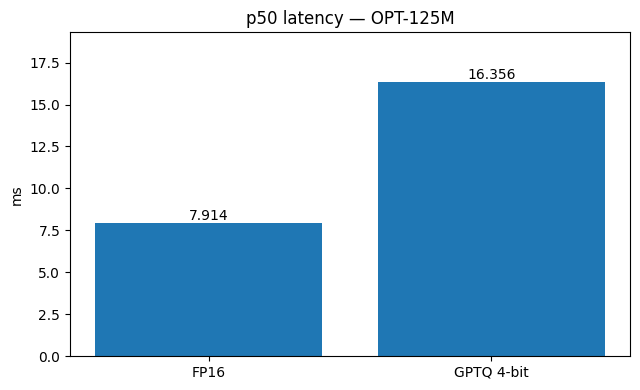

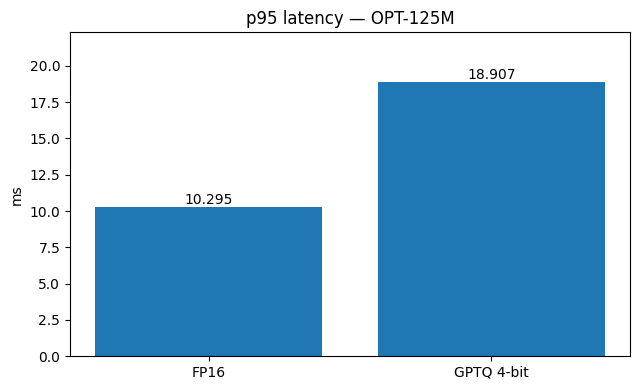

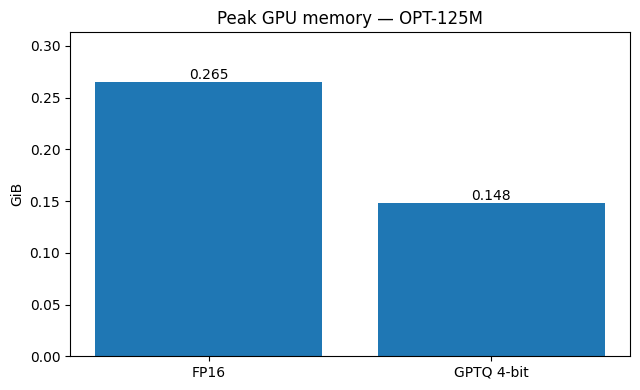

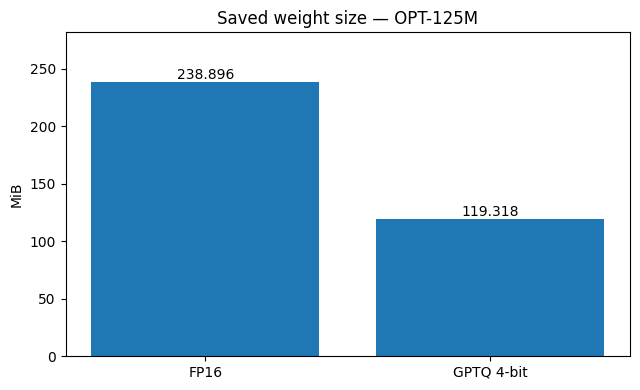

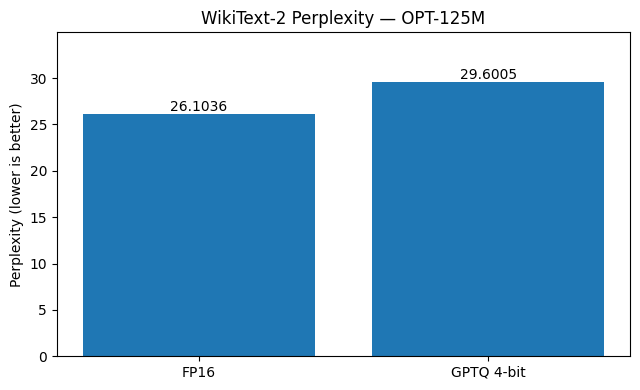

GPTQ COMPARISON FIGURES
Figures saved: 5
✅ p50_ms_comparison.png
✅ p95_ms_comparison.png
✅ peak_gpu_gib_comparison.png
✅ weight_size_mib_comparison.png
✅ wikitext_perplexity_comparison.png
Folder: /content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq/figures


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUT = ROOT / "outputs/part1_gptq"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

with open(OUT / "fp16_vs_gptq_performance.json") as f:
    perf = json.load(f)

with open(OUT / "fp16_vs_gptq_quality.json") as f:
    quality = json.load(f)

fp16 = perf["fp16"]
gptq = perf["gptq_4bit"]

metrics = [
    ("p50 latency", "p50_ms", "ms"),
    ("p95 latency", "p95_ms", "ms"),
    ("Peak GPU memory", "peak_gpu_gib", "GiB"),
    ("Saved weight size", "weight_size_mib", "MiB")
]

# Separate plots avoid mixing incompatible units.
for title, key, unit in metrics:
    values = [fp16[key], gptq[key]]

    fig, ax = plt.subplots(figsize=(6.5, 4))

    bars = ax.bar(
        ["FP16", "GPTQ 4-bit"],
        values
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

    ax.set_title(title + " — OPT-125M")
    ax.set_ylabel(unit)
    ax.set_ylim(0, max(values) * 1.18)

    fig.tight_layout()

    filename = key + "_comparison.png"
    fig.savefig(FIGURES / filename, dpi=220)
    plt.show()
    plt.close(fig)

# Quality comparison
fig, ax = plt.subplots(figsize=(6.5, 4))

ppl_values = [
    quality["fp16"]["perplexity"],
    quality["gptq_4bit"]["perplexity"]
]

bars = ax.bar(
    ["FP16", "GPTQ 4-bit"],
    ppl_values
)

for bar, value in zip(bars, ppl_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

ax.set_ylabel("Perplexity (lower is better)")
ax.set_title("WikiText-2 Perplexity — OPT-125M")
ax.set_ylim(0, max(ppl_values) * 1.18)

fig.tight_layout()
fig.savefig(
    FIGURES / "wikitext_perplexity_comparison.png",
    dpi=220
)
plt.show()
plt.close(fig)

saved = list(FIGURES.glob("*.png"))

print("=" * 60)
print("GPTQ COMPARISON FIGURES")
print("=" * 60)
print("Figures saved:", len(saved))

for path in sorted(saved):
    print("✅", path.name)

print("Folder:", FIGURES)
print("=" * 60)


## Part 1 — Question 8: Final-Environment FP16 Quality Verification

### Objective

Verify the original FP16 model's WikiText-2 loss and perplexity under the same final software environment used for the GPTQ 4-bit model.

### Why This Check Is Necessary

The first FP16 quality evaluation was completed before the GPTQModel installation upgraded PyTorch and Transformers.

Although the model revision and evaluation dataset remained unchanged, software differences can affect numerical results. Therefore, we will repeat only the FP16 quality evaluation without retraining or requantizing either model.

### Experimental Configuration

- Base model: `facebook/opt-125m`
- Model revision: `27dcfa74d334bc871f3234de431e71c6eeba5dd6`
- Precision: FP16
- Dataset: WikiText-2 raw test
- Evaluation window: 1024 tokens
- Stride: 512 tokens
- Expected evaluation tokens: 287,644
- Expected scored tokens: 287,643
- Hardware: NVIDIA L4
- Seed: 1598
- Software: PyTorch 2.15.0, Transformers 5.23.0

### Procedure

1. Load the original FP16 model using the exact recorded revision.
2. Use the same WikiText-2 test text and tokenization settings.
3. Calculate token-weighted next-token negative log-likelihood and perplexity.
4. Compare the new FP16 result against the original baseline.
5. Update the final quality comparison using the same-environment FP16 result.

### Expected Results

A verified FP16 baseline and an updated FP16-versus-GPTQ quality comparison.

Any numerical differences between the original and repeated FP16 evaluations will be reported transparently.


In [ ]:

import gc
import json
import math
import random

from pathlib import Path

import numpy as np
import torch

from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

SID4 = 1598
SEED = SID4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

MODEL_ID = "facebook/opt-125m"
MODEL_REVISION = "27dcfa74d334bc871f3234de431e71c6eeba5dd6"

OUT = Path(
    "/content/drive/MyDrive/DATA266_HW12/outputs/part1_gptq"
)

WINDOW = 1024
STRIDE = 512

assert torch.cuda.is_available()

# ============================================================
# 2. LOAD PREVIOUS RESULTS
# ============================================================

with open(OUT / "fp16_wikitext_metrics.json") as f:
    previous_fp16 = json.load(f)

with open(OUT / "gptq_wikitext_metrics.json") as f:
    gptq_metrics = json.load(f)

# ============================================================
# 3. RELEASE QUANTIZED MODEL FROM GPU
# ============================================================

for name in [
    "quantized_model",
    "gptq_benchmark_model",
    "gptq_model",
    "fp16_model",
    "original_model"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 4. LOAD ORIGINAL FP16 MODEL
# ============================================================

print("Loading original FP16 model...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=torch.float16
).to("cuda:0")

model.eval()

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION
)

# ============================================================
# 5. PREPARE IDENTICAL TEST TOKENS
# ============================================================

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test"
)

test_text = "\n\n".join(dataset["text"])

input_ids = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False,
    truncation=False
)["input_ids"]

assert input_ids.shape[1] == 287644

# ============================================================
# 6. EVALUATE FP16 PERPLEXITY
# ============================================================

seq_len = input_ids.shape[1]

total_nll = 0.0
total_scored = 0
windows = 0
previous_end = 0

print("\nEvaluating FP16 in the final environment...")

for candidate_end in tqdm(
    range(STRIDE, seq_len + STRIDE, STRIDE),
    desc="Final FP16 Verification"
):
    end = min(candidate_end, seq_len)
    begin = max(end - WINDOW, 0)

    target_length = end - previous_end

    if target_length <= 0:
        break

    batch = input_ids[:, begin:end].to("cuda:0")

    labels = batch.clone()
    labels[:, :-target_length] = -100

    scored = int(
        (labels[:, 1:] != -100).sum().item()
    )

    with torch.inference_mode():
        output = model(
            input_ids=batch,
            labels=labels,
            use_cache=False
        )

    if scored > 0:
        loss = float(output.loss.item())

        assert math.isfinite(loss)

        total_nll += loss * scored
        total_scored += scored

    windows += 1
    previous_end = end

    if end == seq_len:
        break

average_nll = total_nll / total_scored
perplexity = math.exp(average_nll)

# ============================================================
# 7. VALIDATE MATCHING EVALUATION CONDITIONS
# ============================================================

assert total_scored == gptq_metrics["scored_tokens"]
assert windows == gptq_metrics["evaluation_windows"]
assert WINDOW == gptq_metrics["window_length"]
assert STRIDE == gptq_metrics["stride"]

# ============================================================
# 8. SAVE FINAL RESULTS
# ============================================================

final_fp16 = {
    "model_id": MODEL_ID,
    "revision": MODEL_REVISION,
    "precision": "FP16",
    "dataset": "Salesforce/wikitext",
    "dataset_config": "wikitext-2-raw-v1",
    "dataset_split": "test",
    "average_nll": average_nll,
    "perplexity": perplexity,
    "total_evaluation_tokens": seq_len,
    "scored_tokens": total_scored,
    "evaluation_windows": windows,
    "window_length": WINDOW,
    "stride": STRIDE,
    "seed": SEED,
    "torch_version": torch.__version__
}

with open(
    OUT / "fp16_wikitext_final_environment.json", "w"
) as f:
    json.dump(final_fp16, f, indent=2)

ppl_change = (
    gptq_metrics["perplexity"] - perplexity
)

ppl_change_pct = (
    100 * ppl_change / perplexity
)

final_comparison = {
    "fp16": final_fp16,
    "gptq_4bit": gptq_metrics,
    "perplexity_absolute_change": ppl_change,
    "perplexity_percent_change": ppl_change_pct
}

with open(
    OUT / "fp16_vs_gptq_quality_final.json", "w"
) as f:
    json.dump(final_comparison, f, indent=2)

# ============================================================
# 9. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FINAL-ENVIRONMENT QUALITY COMPARISON")
print("=" * 65)

print(
    f"Previous FP16 perplexity: "
    f"{previous_fp16['perplexity']:.4f}"
)

print(
    f"Verified FP16 perplexity: "
    f"{perplexity:.4f}"
)

print(
    f"GPTQ 4-bit perplexity: "
    f"{gptq_metrics['perplexity']:.4f}"
)

print(
    f"Verified FP16 average NLL: "
    f"{average_nll:.6f}"
)

print(f"Absolute PPL change: {ppl_change:+.4f}")
print(f"Percentage PPL change: {ppl_change_pct:+.2f}%")

print("Scored tokens:", total_scored)
print("Evaluation windows:", windows)

print("\n✅ Final FP16 quality results saved.")
print("✅ Final GPTQ quality comparison saved.")

print("=" * 65)

del model
gc.collect()
torch.cuda.empty_cache()


Loading original FP16 model...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]


Evaluating FP16 in the final environment...


Final FP16 Verification:   0%|          | 0/562 [00:00<?, ?it/s]


FINAL-ENVIRONMENT QUALITY COMPARISON
Previous FP16 perplexity: 26.1036
Verified FP16 perplexity: 26.1023
GPTQ 4-bit perplexity: 29.6005
Verified FP16 average NLL: 3.262023
Absolute PPL change: +3.4983
Percentage PPL change: +13.40%
Scored tokens: 287643
Evaluation windows: 562

✅ Final FP16 quality results saved.
✅ Final GPTQ quality comparison saved.



## Step 16 — Final GPTQ Metrics and Reporting



In [ ]:
import json
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUT = ROOT / "outputs/part1_gptq"

def read_json(name):
    path = OUT / name
    assert path.is_file(), f"Missing file: {path}"
    with open(path, encoding="utf-8") as f:
        return json.load(f)

# Read actual saved results.
fp16 = read_json("fp16_wikitext_final_environment.json")
gptq = read_json("gptq_wikitext_metrics.json")
performance = read_json("fp16_vs_gptq_performance.json")
quantization = read_json("gptq_quantization_result.json")

fp16_perf = performance["fp16"]
gptq_perf = performance["gptq_4bit"]

# Calculate directly from measured results.
ppl_change = (
    (gptq["perplexity"] / fp16["perplexity"]) - 1
) * 100

latency_ratio = (
    gptq_perf["p50_ms"] / fp16_perf["p50_ms"]
)

weight_reduction = (
    1 - gptq_perf["weight_size_mib"]
    / fp16_perf["weight_size_mib"]
) * 100

memory_reduction = (
    1 - gptq_perf["peak_gpu_gib"]
    / fp16_perf["peak_gpu_gib"]
) * 100

assert fp16["scored_tokens"] == gptq["scored_tokens"]
assert fp16["evaluation_windows"] == gptq["evaluation_windows"]

report = f"""# DATA 266 — Homework 12
## Part 1: GPTQ Quantization — Final Metrics

### 1. Experiment Information

| Parameter | Value |
|---|---|
| SID4 / SEED | 1598 |
| SLICE | 598 |
| HP_ID | 2 |
| CLS_A / CLS_B | 8 / 5 |
| Base model | facebook/opt-125m |
| Model revision | 27dcfa74d334bc871f3234de431e71c6eeba5dd6 |
| Original precision | FP16 |
| Quantization | GPTQ, 4-bit |
| Group size | 128 |
| Calibration samples | 128 |
| Calibration dataset | WikiText-2 training split |
| Evaluation dataset | WikiText-2 raw test |
| GPU | NVIDIA L4 |
| Quantization library | GPTQModel 7.12.0 |

**Model approval:** OPT-125M was selected from the linked
Hugging Face documentation. Instructor approval has not yet
been confirmed.

### 2. Model Quality

| Metric | FP16 | GPTQ 4-bit |
|---|---:|---:|
| Average NLL | {fp16['average_nll']:.6f} | {gptq['average_nll']:.6f} |
| Perplexity | {fp16['perplexity']:.4f} | {gptq['perplexity']:.4f} |
| Scored tokens | {fp16['scored_tokens']:,} | {gptq['scored_tokens']:,} |
| Evaluation windows | {fp16['evaluation_windows']} | {gptq['evaluation_windows']} |

**Perplexity change:** {ppl_change:+.2f}%

Both evaluations use the same tokenizer, test split, 1024-token
window length, 512-token stride, and final software environment.

### 3. Inference Performance

| Metric | FP16 | GPTQ 4-bit |
|---|---:|---:|
| p50 latency (ms) | {fp16_perf['p50_ms']:.3f} | {gptq_perf['p50_ms']:.3f} |
| p95 latency (ms) | {fp16_perf['p95_ms']:.3f} | {gptq_perf['p95_ms']:.3f} |
| Peak allocated GPU memory (GiB) | {fp16_perf['peak_gpu_gib']:.3f} | {gptq_perf['peak_gpu_gib']:.3f} |
| Saved weight size (MiB) | {fp16_perf['weight_size_mib']:.3f} | {gptq_perf['weight_size_mib']:.3f} |

**Median latency ratio (GPTQ / FP16):** {latency_ratio:.2f}x

**Weight-size reduction:** {weight_reduction:.2f}%

**Peak GPU memory reduction:** {memory_reduction:.2f}%

### 4. Benchmark Methodology

- Same NVIDIA L4 GPU
- Batch size: {fp16_perf['batch_size']}
- Input length: {fp16_perf['sequence_length']} tokens
- Warm-up iterations: {fp16_perf['warmup_runs']}
- Timed iterations: {fp16_perf['timed_runs']}
- CUDA synchronization before and after timing
- Forward-pass logits evaluation without KV cache
- Random input tokens generated with SEED 1598
- Models benchmarked separately

The reported memory is peak PyTorch GPU memory allocation
during inference, not total GPU memory or loading-time peak.

### 5. Quantization Details

- Quantization duration: {quantization['elapsed_seconds']:.2f} seconds
- Quantization bits: {quantization['bits']}
- Group size: {quantization['group_size']}
- Descending activation ordering: {quantization['desc_act']}
- Calibration sample count: {quantization['calibration_samples']}

### 6. Findings

GPTQ reduced saved model weight size by {weight_reduction:.2f}%
and peak allocated GPU memory by {memory_reduction:.2f}%.

However, perplexity increased by {ppl_change:.2f}%, and
GPTQ median forward-pass latency was {latency_ratio:.2f}
times that of FP16.

Therefore, for this model and tested workload, GPTQ provides
a memory and storage advantage but does not improve inference
latency or language-modeling quality.

### 7. Limitations

- GPTQModel warned that calibration sample count and average
  sequence length were below its recommendations.
- Benchmark timings measure forward-pass latency, not text
  generation tokens per second.
- Results may differ for larger models or other hardware.
- The selected model's instructor approval remains unconfirmed.
- Timing and GPU measurements can vary between runs.

### 8. Reproducibility

All measurements originate from executed experiment outputs.
Saved checkpoints, configurations, JSON metrics, notebook
outputs, and installation logs should accompany the submission.

Generated: {datetime.now(timezone.utc).isoformat()}
"""

report_path = ROOT / "METRICS_GPTQ.md"

report_path.write_text(report, encoding="utf-8")

print("=" * 65)
print("DATA266 HW12 — METRICS REPORT")
print("=" * 65)
print("Report generated:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")

print("\nFINAL VERIFIED VALUES")
print(f"FP16 PPL: {fp16['perplexity']:.4f}")
print(f"GPTQ PPL: {gptq['perplexity']:.4f}")
print(f"PPL change: {ppl_change:+.2f}%")
print(f"GPTQ / FP16 latency ratio: {latency_ratio:.2f}x")
print(f"Weight reduction: {weight_reduction:.2f}%")
print(f"GPU memory reduction: {memory_reduction:.2f}%")

print("\n✅ GPTQ metrics report generated successfully.")
print("=" * 65)

DATA266 HW12 — METRICS REPORT
Report generated: /content/drive/MyDrive/DATA266_HW12/METRICS_GPTQ.md
Report size: 3124 bytes

FINAL VERIFIED VALUES
FP16 PPL: 26.1023
GPTQ PPL: 29.6005
PPL change: +13.40%
GPTQ / FP16 latency ratio: 2.07x
Weight reduction: 50.05%
GPU memory reduction: 44.21%

✅ GPTQ metrics report generated successfully.



## Step 17 — GPTQ Execution Log and Error Documentation



In [ ]:
import json
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/DATA266_HW12")
OUT = ROOT / "outputs/part1_gptq"
LOGS = OUT / "logs"

def load_json(filename):
    path = OUT / filename
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    return None

sections = []

def add_section(title, content):
    sections.append(
        "\n" + "=" * 72 + "\n"
        + title + "\n"
        + "=" * 72 + "\n"
        + str(content).rstrip() + "\n"
    )

add_section(
    "DATA266 HW12 — GPTQ RUN LOG DRAFT",
    (
        "Generated UTC: "
        + datetime.now(timezone.utc).isoformat()
        + "\nSID4 / SEED: 1598"
        + "\nGPU: NVIDIA L4"
        + "\nIMPORTANT: JSON-derived summaries below are NOT "
          "verbatim console transcripts."
    )
)

# Include genuine logs already captured on disk.
for filename in [
    "gptq_dependency_dry_run.txt",
    "gptq_installation_log.txt",
    "gptq_quantization_error.txt"
]:
    path = LOGS / filename

    if path.is_file():
        add_section(
            f"CAPTURED LOG — {filename}",
            path.read_text(
                encoding="utf-8",
                errors="replace"
            )
        )

# Add structured results, explicitly identified as summaries.
files = [
    ("Base model verification", "original_model_info.json"),
    ("Quantization result", "gptq_quantization_result.json"),
    ("Checkpoint verification", "gptq_checkpoint_verification.json"),
    ("Final FP16 quality", "fp16_wikitext_final_environment.json"),
    ("GPTQ quality", "gptq_wikitext_metrics.json"),
    ("FP16 performance", "fp16_performance.json"),
    ("GPTQ performance", "gptq_performance.json")
]

missing = []

for title, filename in files:
    content = load_json(filename)

    if content is None:
        missing.append(filename)
    else:
        add_section(
            f"SAVED RESULT SUMMARY — {title}",
            json.dumps(content, indent=2)
        )

# Record the known import failure as a summary.
# Do not misrepresent this as the original traceback.
add_section(
    "KNOWN ERROR — TORCHAUDIO CUDA MISMATCH",
    (
        "Observed during post-installation GPTQ import.\n"
        "PyTorch CUDA build: 13.2\n"
        "TorchAudio CUDA build: 13.0\n"
        "Symptom: AutoProcessor import failed because "
        "TorchAudio initialization raised RuntimeError.\n"
        "Correction: pip uninstall -y torchaudio\n"
        "Verification: GPTQModel and QuantizeConfig "
        "imports subsequently passed.\n"
        "The original traceback must be retained from "
        "the executed notebook."
    )
)

add_section(
    "RUN LOG COMPLETENESS",
    (
        "This draft contains the captured installation "
        "and dependency logs plus saved experiment summaries.\n"
        "It does not yet contain every original console "
        "line from quantization, evaluation, and benchmarking.\n"
        "Export those original outputs from the executed "
        "notebook or capture them during a clean reproducibility "
        "run before final submission.\n"
        "Do not substitute these summaries for the required "
        "verbatim run output."
    )
)

draft_path = ROOT / "RUN_LOG_GPTQ_DRAFT.txt"

draft_path.write_text(
    "\n".join(sections),
    encoding="utf-8"
)

print("=" * 65)
print("DATA266 HW12 — GPTQ RUN LOG DRAFT")
print("=" * 65)

print("File:", draft_path)
print("Size:", draft_path.stat().st_size, "bytes")
print("Sections:", len(sections))
print("Missing result files:", missing if missing else "None")

print("\n✅ Available evidence collected.")
print("⚠️ Full original notebook console outputs still needed.")
print("=" * 65)

DATA266 HW12 — GPTQ RUN LOG DRAFT
File: /content/drive/MyDrive/DATA266_HW12/RUN_LOG_GPTQ_DRAFT.txt
Size: 47551 bytes
Sections: 12
Missing result files: None

✅ Available evidence collected.
⚠️ Full original notebook console outputs still needed.
